# Lab Regressions
I noticed a couple weird things with the labs and want to investigate further. For example, vitamin D2 only has 7 observations that are numbers other than 4.0. Weird.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import arivale_data_interface as adi
# apply settings so the lib knows where the data is
adi.apply_isb_config()

# For regressions
from regression_functions import *
from rich.progress import track
from statsmodels.formula.api import ols
from statsmodels.stats.multitest import multipletests

# Read in clean lab data

In [2]:
labs_clean = pd.read_csv("data/clincal_chems_abx_users_clean.csv")

In [3]:
labs_clean.public_client_id.nunique()

2347

In [4]:
labs_clean.columns[0:29]

Index(['public_client_id', 'PC1', 'PC2', 'PC3', 'PC4', 'PC5',
       'days_in_program', 'meds_blood_sugar', 'meds_cholesterol', 'sex', 'age',
       'BMI_CALC', 'abx_recency', 'eGFR', 'centered_eGFR', 'abx_recency_three',
       'abx_recency_twelve', 'abx_year', 't2dm_chol', 'vendor',
       'vendor_observation_id', 'observation_id', 'reflexive', 'fasting',
       'days_since_first_call', 'days_since_first_draw', 'month', 'weekday',
       'season'],
      dtype='object')

In [5]:
lab_features = labs_clean.columns[29:]

## Identify which clinical chemistry tests were offered by each vendor

In [6]:
quest = labs_clean[labs_clean['vendor'] == 'Quest']
labcorp = labs_clean[labs_clean['vendor'] == 'LCA']

**Not offered by Quest: Lapcorp only tests**

In [7]:
quest[lab_features].isna().all().sum()

8

In [8]:
not_offered_quest = quest[lab_features].isna().all().index[quest[lab_features].isna().all()].tolist()

**Not offered by labcorp: Quest only tests**

In [9]:
labcorp[lab_features].isna().all().sum()

16

In [10]:
not_offered_labcorp = labcorp[lab_features].isna().all().index[labcorp[lab_features].isna().all()].tolist()

**Offered by both vendors**

In [11]:
individual_vendors = not_offered_labcorp + not_offered_quest

In [12]:
shared_labs = list(set(lab_features) - set(individual_vendors))

# Perform Regressions
Remember, we should test the vendor specific tests separately and then concatenate tables and FDR correct at the end.

In [13]:
len(shared_labs)

70

In [14]:
# shared_labs

In [15]:
len(not_offered_labcorp) # Quest specific

16

In [16]:
not_offered_labcorp

['ANTIOXIDCAP_TOTAL',
 'ARSENIC_BLOOD',
 'BILIRUBIN_DIRECT',
 'BILIRUBIN_INDIRECT',
 'COPPER_RBC',
 'HDLLARGE',
 'LACTICDEHYDROGENASE',
 'LDLMEDIUM',
 'MANGANESE_SERUM',
 'MPV',
 'PAI_1ANTIGEN_QNT',
 'PHOSPHORUSINORGANIC',
 'SELENIUM_SERUM',
 'SUPEROXDISMUTSOD',
 'VITAMIND3_25_OH',
 'ZINC_RBC']

In [17]:
len(not_offered_quest) # LCA specific

8

In [18]:
not_offered_quest

['DPA',
 'HDLPARTICLENUMBER',
 'LINOLEIC_ACID',
 'LPIR_SCORE',
 'MAGNESIUM_SERUM',
 'OMEGA_3_TOTAL',
 'OMEGA_6_TOTAL',
 'OXLDL']

## Unadjusted (Model 1)
Here we are just adjusting for batch effects due to vendor. 

In [19]:
forumla_unadjusted_vendor = "{feature} ~ C(abx_recency) + vendor" # This is so I can do the shared labs
forumla_unadjusted = "{feature} ~ C(abx_recency)"
abx_term_three = "C(abx_recency)[T.three]"
abx_term_twelve = "C(abx_recency)[T.twelve]"

### Unadjusted (Model 1): 3 month group

In [20]:
tests_abx_three_shared = run_tests(shared_labs, labs_clean, forumla_unadjusted_vendor, abx_term_three)
tests_abx_three_quest = run_tests(list(not_offered_labcorp), labs_clean, forumla_unadjusted, abx_term_three)
tests_abx_three_labcorp = run_tests(list(not_offered_quest), labs_clean, forumla_unadjusted, abx_term_three)

# Concat
tests_three = pd.concat([tests_abx_three_shared, tests_abx_three_quest, tests_abx_three_labcorp])

# Apply FDR correctly since we concatenated 3 tables
tests_three.drop(columns='q', inplace=True) 
tests_three.loc[:, "q"] = multipletests(tests_three.p, method="fdr_bh")[1]
tests_three.sort_values(by='q').head()

Output()

Output()

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
ALKALINEPHOSPHATASE,ALKALINEPHOSPHATASE,3.515022,1.249306,2.813580,1.065162,5.964881,0.004940,2347.0,0.306178
IL_6,IL_6,2.242203,0.823385,2.723152,0.627559,3.856846,0.006514,2335.0,0.306178
ADIPONECTIN_SERUM,ADIPONECTIN_SERUM,0.783639,0.374172,2.094328,0.049896,1.517383,0.036338,2345.0,0.422022
POTASSIUM,POTASSIUM,-0.045779,0.018913,-2.420512,-0.082867,-0.008691,0.015574,2347.0,0.422022
FERRITIN,FERRITIN,-16.979001,7.436567,-2.283177,-31.561947,-2.396056,0.022509,2344.0,0.422022


### Unadjusted: 12 months

In [21]:
tests_abx_twelve_shared = run_tests(shared_labs, labs_clean, forumla_unadjusted_vendor, abx_term_twelve)
tests_abx_twelve_quest = run_tests(list(not_offered_labcorp), labs_clean, forumla_unadjusted, abx_term_twelve)
tests_abx_twelve_labcorp = run_tests(list(not_offered_quest), labs_clean, forumla_unadjusted, abx_term_twelve)

# Concat
tests_twelve = pd.concat([tests_abx_twelve_shared, tests_abx_twelve_quest, tests_abx_twelve_labcorp])

# Apply FDR
tests_twelve.drop(columns='q', inplace=True) 
tests_twelve.loc[:, "q"] = multipletests(tests_twelve.p, method="fdr_bh")[1]
tests_twelve.sort_values(by='q').head()

Output()

Output()

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
QUICKI,QUICKI,-0.007578,0.001805,-4.197149,-0.011118,-0.004037,0.000028,2347.0,0.002636
BILIRUBIN_TOTAL,BILIRUBIN_TOTAL,-0.050229,0.014937,-3.362737,-0.079520,-0.020938,0.000784,2347.0,0.036855
WHITECELLCOUNT,WHITECELLCOUNT,0.196276,0.076641,2.560987,0.045985,0.346567,0.010500,2341.0,0.159951
CRPHIGHSENSITIVITY,CRPHIGHSENSITIVITY,0.672555,0.269477,2.495783,0.144118,1.200993,0.012636,2347.0,0.159951
LDL_SIZE,LDL_SIZE,-0.067426,0.027047,-2.492924,-0.120464,-0.014387,0.012738,2337.0,0.159951


In [22]:
# # Define labs to use for mediation
# mediation_labs = tests_twelve[tests_twelve.q < 0.2].feature.tolist()
# mediation_labs

## Adjusted full model

In [23]:
labs_clean['centered_BMI'] = labs_clean['BMI_CALC'].apply(lambda x: x - labs_clean['BMI_CALC'].mean())

<Axes: >

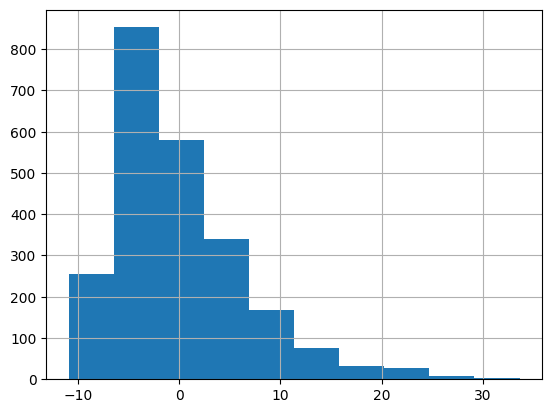

In [24]:
labs_clean['centered_BMI'].hist()

In [25]:
labs_clean['BMI_CALC'].mean()

27.905615053300647

In [26]:
forumla_full_vendor = ("{feature} ~ C(abx_recency) + centered_BMI + sex + age + C(meds_blood_sugar) + C(meds_cholesterol)"
                        " + PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR + vendor")
forumla_full = ("{feature} ~ C(abx_recency) + centered_BMI + sex + age + C(meds_blood_sugar) + C(meds_cholesterol)"
                " + PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR")

### 3 months

In [27]:
tests_abx_three_shared_full = run_tests(shared_labs, labs_clean, forumla_full_vendor, abx_term_three)
tests_abx_three_quest_full = run_tests(list(not_offered_labcorp), labs_clean, forumla_full, abx_term_three)
tests_abx_three_labcorp_full = run_tests(list(not_offered_quest), labs_clean, forumla_full, abx_term_three)

# Concat
tests_three_full = pd.concat([tests_abx_three_shared_full, tests_abx_three_quest_full, tests_abx_three_labcorp_full])

# FDR correct
tests_three_full.drop(columns='q', inplace=True) 
tests_three_full.loc[:, "q"] = multipletests(tests_three_full.p, method="fdr_bh")[1]
tests_three_full.sort_values(by='q').head()

Output()

Output()

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
MONOCYTES,MONOCYTES,0.273955,0.115895,2.363815,0.046686,0.501224,0.018170,2339.0,0.853976
IL_6,IL_6,2.149433,0.829873,2.590074,0.522062,3.776803,0.009656,2335.0,0.853976
GLUTATHIONE_TOTAL,GLUTATHIONE_TOTAL,-7.712929,5.097656,-1.513034,-17.716923,2.291066,0.130604,963.0,0.967052
ALAT_SGPT_,ALAT_SGPT_,1.226929,0.810268,1.514226,-0.361992,2.815849,0.130104,2347.0,0.967052
BILIRUBIN_DIRECT,BILIRUBIN_DIRECT,-0.015170,0.008863,-1.711678,-0.032584,0.002243,0.087584,508.0,0.967052


In [28]:
tests_three_full.sort_values(by='q')

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
MONOCYTES,MONOCYTES,0.273955,0.115895,2.363815,0.046686,0.501224,0.018170,2339.0,0.853976
IL_6,IL_6,2.149433,0.829873,2.590074,0.522062,3.776803,0.009656,2335.0,0.853976
GLUTATHIONE_TOTAL,GLUTATHIONE_TOTAL,-7.712929,5.097656,-1.513034,-17.716923,2.291066,0.130604,963.0,0.967052
ALAT_SGPT_,ALAT_SGPT_,1.226929,0.810268,1.514226,-0.361992,2.815849,0.130104,2347.0,0.967052
BILIRUBIN_DIRECT,BILIRUBIN_DIRECT,-0.015170,0.008863,-1.711678,-0.032584,0.002243,0.087584,508.0,0.967052
...,...,...,...,...,...,...,...,...,...
OMEGA_3_TOTAL,OMEGA_3_TOTAL,-0.004014,0.077483,-0.051799,-0.155979,0.147952,0.958694,1838.0,0.997531
BASOPHILS,BASOPHILS,0.001283,0.029828,0.043013,-0.057210,0.059776,0.965695,2339.0,0.997531
ZINC,ZINC,-0.142766,13.077132,-0.010917,-25.787653,25.502122,0.991291,2204.0,0.999422
A_GRATIO,A_GRATIO,0.000269,0.015907,0.016918,-0.030924,0.031462,0.986503,2347.0,0.999422


### 12 months

In [29]:
tests_abx_twelve_shared_full = run_tests(shared_labs, labs_clean, forumla_full_vendor, abx_term_twelve)
tests_abx_twelve_quest_full = run_tests(list(not_offered_labcorp), labs_clean, forumla_full, abx_term_twelve)
tests_abx_twelve_labcorp_full = run_tests(list(not_offered_quest), labs_clean, forumla_full, abx_term_twelve)

# Concat
tests_twelve_full = pd.concat([tests_abx_twelve_shared_full, tests_abx_twelve_quest_full, tests_abx_twelve_labcorp_full])

# FDR correct
tests_twelve_full.drop(columns='q', inplace=True) 
tests_twelve_full.loc[:, "q"] = multipletests(tests_twelve_full.p, method="fdr_bh")[1]
tests_twelve_full.sort_values(by='q').head()

Output()

Output()

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
MONOCYTES,MONOCYTES,0.232011,0.095548,2.428209,0.044642,0.419380,0.015249,2339.0,0.716704
BILIRUBIN_TOTAL,BILIRUBIN_TOTAL,-0.037660,0.014225,-2.647507,-0.065554,-0.009766,0.008163,2347.0,0.716704
MONOCYTESABSOLUTE,MONOCYTESABSOLUTE,0.013590,0.006374,2.132131,0.001091,0.026088,0.033101,2339.0,0.856965
BILIRUBIN_DIRECT,BILIRUBIN_DIRECT,-0.014660,0.007098,-2.065398,-0.028606,-0.000714,0.039406,508.0,0.856965
QUICKI,QUICKI,-0.002763,0.001381,-2.000304,-0.005472,-0.000054,0.045583,2347.0,0.856965
